# 01 — Exploratory data analysis

Goal: understand the Telco churn data **before** modelling, and document why some columns must never be used as features (leakage).

Figures are saved to `reports/figures/`. Run with `make eda` or interactively.

In [2]:
import sys
print(sys.executable)

c:\Users\lenovo\Desktop\churn-mlops\.venv\Scripts\python.exe


In [3]:
import seaborn
print(seaborn.__version__)

0.13.2


In [4]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

def find_root(start=None):
    """Project root = first parent folder containing the Makefile (works from notebooks/ or via make)."""
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "Makefile").exists():
            return cand
    return p

ROOT = find_root()
RAW_PATH = Path(os.environ.get("CHURN_DATA_PATH", ROOT / "data" / "raw" / "Telco_customer_churn.csv"))

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "Churn Value"
print("Project root:", ROOT)
print("Data file   :", RAW_PATH)

Project root: C:\Users\lenovo\Desktop\churn-mlops
Data file   : C:\Users\lenovo\Desktop\churn-mlops\data\raw\Telco_customer_churn.csv


In [ ]:
df = pd.read_csv(RAW_PATH, sep=";")

print(df.columns.tolist())

['CustomerID;Count;Country;State;City;Zip Code;Lat Long;Latitude;Longitude;Gender;Senior Citizen;Partner;Dependents;Tenure Months;Phone Service;Multiple Lines;Internet Service;Online Security;Online Backup;Device Protection;Tech Support;Streaming TV;Streaming Movies;Contract;Paperless Billing;Payment Method;Monthly Charges;Total Charges;Churn Label;Churn Value;Churn Score;CLTV;Churn Reason']


## 1. Load and basic cleaning

In [8]:
df = pd.read_csv(RAW_PATH, sep=";")
df.columns = df.columns.str.strip()
df = df.rename(columns={"Monthly Charge": "Monthly Charges"})   # tolerate the shorter name

# Total Charges is stored as text; blanks (a single space) appear for brand-new customers
tc = pd.to_numeric(df["Total Charges"], errors="coerce")
print("Blank Total Charges:", int(tc.isna().sum()),
      "| tenure values for those rows:", sorted(df.loc[tc.isna(), "Tenure Months"].unique()))
df["Total Charges"] = tc.fillna(0.0)
df["Churn"] = df[TARGET].map({0: "Stayed", 1: "Churned"})

print("Shape:", df.shape)
df.head()

Blank Total Charges: 6719 | tenure values for those rows: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(65), np.int64(66), np.int64(67),

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason,Churn
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783","33,964131","-118,272783",Male,...,Yes,Mailed check,"53,85",0.0,Yes,1,86,3239,Competitor made better offer,Churned
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742","34,059281","-118,307420",Female,...,Yes,Electronic check,"70,7",0.0,Yes,1,67,2701,Moved,Churned
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953","34,048013","-118,293953",Female,...,Yes,Electronic check,"99,65",0.0,Yes,1,86,5372,Moved,Churned
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709","34,062125","-118,315709",Female,...,Yes,Electronic check,"104,8",0.0,Yes,1,84,5003,Moved,Churned
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293","34,039224","-118,266293",Male,...,Yes,Bank transfer (automatic),"103,7",0.0,Yes,1,89,5340,Competitor had better devices,Churned


In [9]:
overview = pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unique": df.nunique(), "n_missing": df.isna().sum()})
overview

,dtype,n_unique,n_missing
CustomerID,str,7043,0
Count,int64,1,0
Country,str,1,0
State,str,1,0
City,str,1129,0
Zip Code,int64,1652,0
Lat Long,str,1652,0
Latitude,str,1652,0
Longitude,str,1651,0
Gender,str,2,0


## 2. Target balance

Overall churn rate: 26.5%  (1869 churned / 7043 customers)


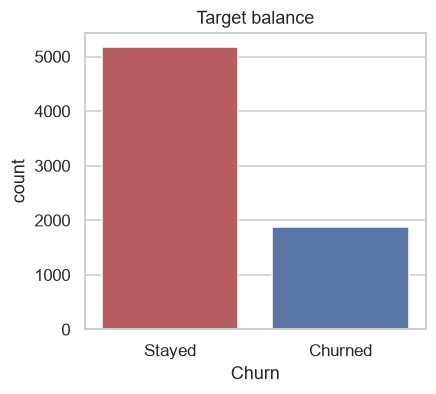

In [10]:
overall_rate = df[TARGET].mean() * 100
print(f"Overall churn rate: {overall_rate:.1f}%  ({int(df[TARGET].sum())} churned / {len(df)} customers)")

fig, ax = plt.subplots(figsize=(4, 3.5))
sns.countplot(data=df, x="Churn", order=["Stayed", "Churned"], ax=ax, palette=["#4c72b0", "#c44e52"], hue="Churn", legend=False)
ax.set_title("Target balance")
fig.savefig(FIG_DIR / "01_target_balance.png", bbox_inches="tight")
plt.show()

The classes are imbalanced, so accuracy is misleading — this is why the project compares precision, recall, F1 and ROC-AUC, and uses stratified splits.

## 3. Churn rate by categorical feature

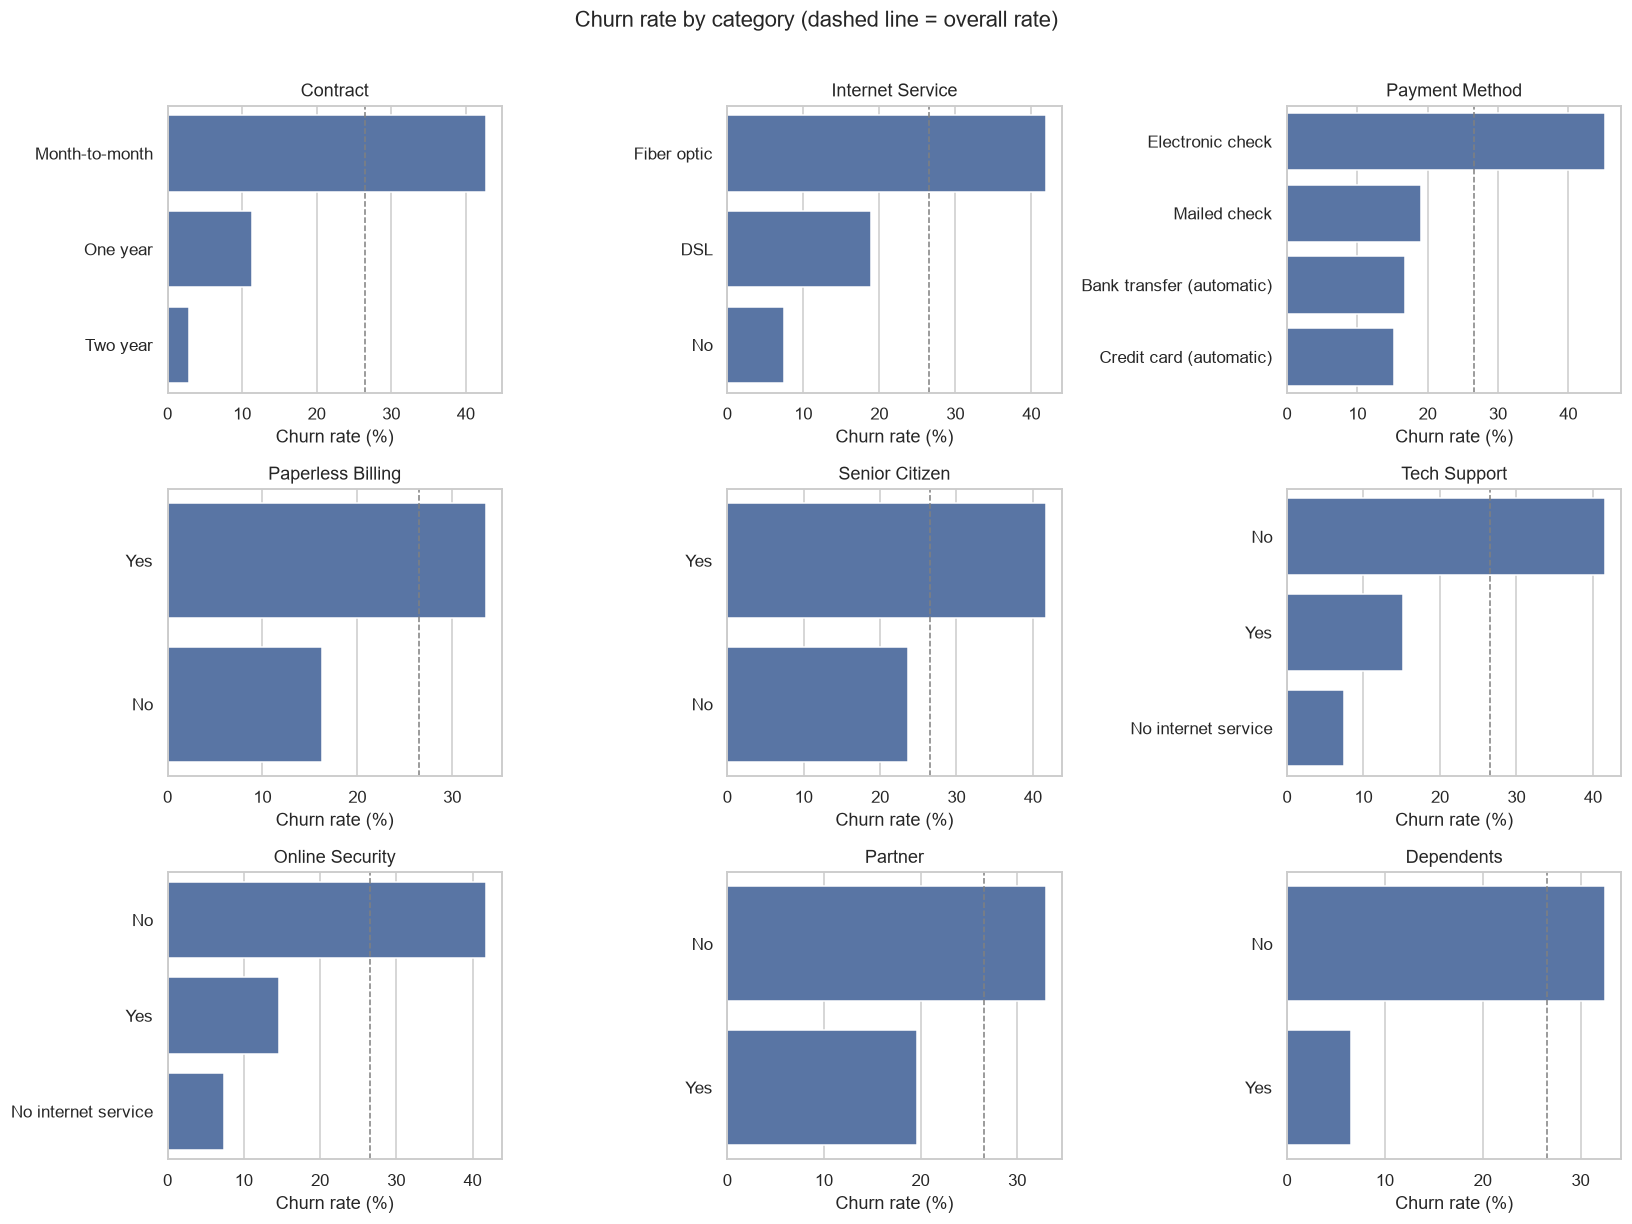

In [11]:
cat_cols = ["Contract", "Internet Service", "Payment Method", "Paperless Billing", "Senior Citizen",
            "Tech Support", "Online Security", "Partner", "Dependents"]
cat_cols = [c for c in cat_cols if c in df.columns]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = (df.groupby(col)[TARGET].mean() * 100).sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index.astype(str), orient="h", ax=ax, color="#4c72b0")
    ax.axvline(overall_rate, ls="--", c="grey", lw=1)
    ax.set_title(col)
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel("")
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
fig.suptitle("Churn rate by category (dashed line = overall rate)", y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_churn_by_category.png", bbox_inches="tight")
plt.show()

## 4. Numeric features

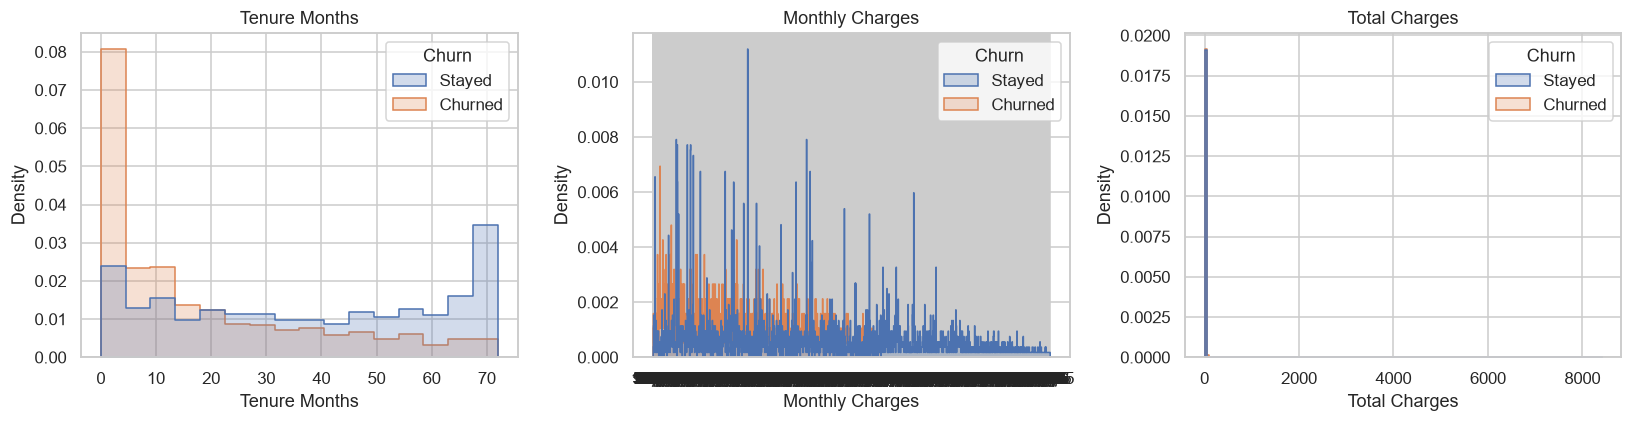

In [12]:
num_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Churn", element="step", stat="density", common_norm=False, hue_order=["Stayed", "Churned"], ax=ax)
    ax.set_title(col)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_numeric_distributions.png", bbox_inches="tight")
plt.show()

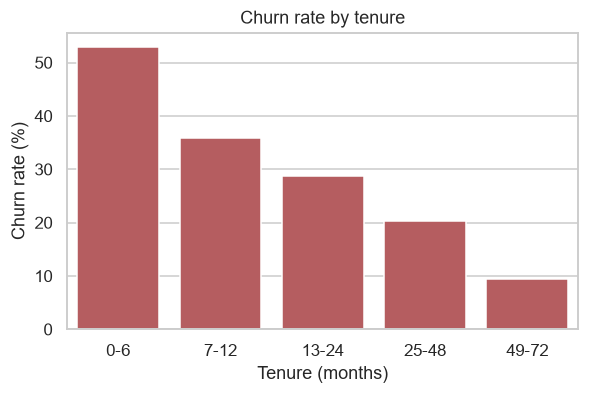

In [13]:
bins = [-1, 6, 12, 24, 48, 72]
labels = ["0-6", "7-12", "13-24", "25-48", "49-72"]
df["Tenure bucket"] = pd.cut(df["Tenure Months"], bins=bins, labels=labels)
by_bucket = df.groupby("Tenure bucket", observed=True)[TARGET].mean() * 100

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(x=by_bucket.index.astype(str), y=by_bucket.values, ax=ax, color="#c44e52")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn rate by tenure")
fig.savefig(FIG_DIR / "04_churn_by_tenure.png", bbox_inches="tight")
plt.show()

In [15]:
print(df[num_cols].dtypes)

Tenure Months        int64
Monthly Charges        str
Total Charges      float64
dtype: object


In [19]:
df["Monthly Charges"] = (
    df["Monthly Charges"]
    .astype(str)
    .str.replace(",", ".", regex=False)
)

df["Monthly Charges"] = pd.to_numeric(
    df["Monthly Charges"],
    errors="coerce"
)

print(df[["Monthly Charges"]].dtypes)

Monthly Charges    float64
dtype: object


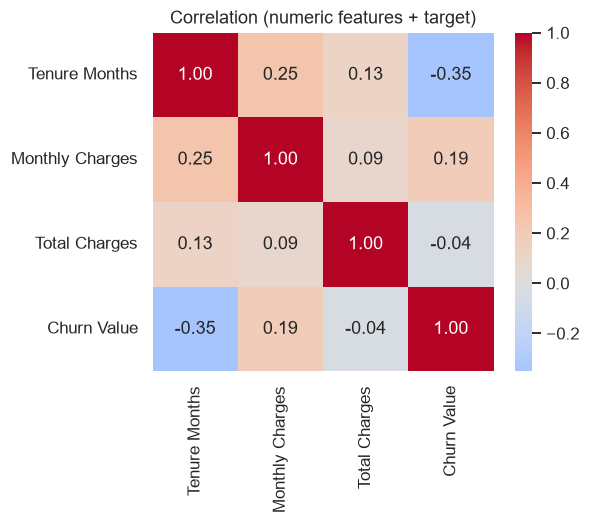

In [20]:
corr = df[num_cols + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation (numeric features + target)")
fig.savefig(FIG_DIR / "05_correlation.png", bbox_inches="tight")
plt.show()

## 5. Why some columns must be excluded (leakage)

A feature is **leaky** if it would not be available — or would not be independent of the outcome — at the moment we want to make a prediction.

In [21]:
rows = []
for col in ["Churn Score", "CLTV"]:
    if col in df.columns:
        rows.append({"column": col, "ROC-AUC used alone": round(roc_auc_score(df[TARGET], df[col]), 3)})
pd.DataFrame(rows)

,column,ROC-AUC used alone
0,Churn Score,0.942
1,CLTV,0.419


- **Churn Score** is produced by IBM SPSS Modeler with churn-related information. If it alone ranks churners almost as well as our whole model, using it would just copy someone else's model (and may not exist for new customers).
- **CLTV** is computed from corporate formulas that include expected churn/tenure, so it is only partly independent of the outcome. Excluded by default.
- **Churn Label / Churn Value**: the target itself.
- **Churn Reason** only exists for customers who already left. It is useful for *analysis* (below) but can never be a model input.

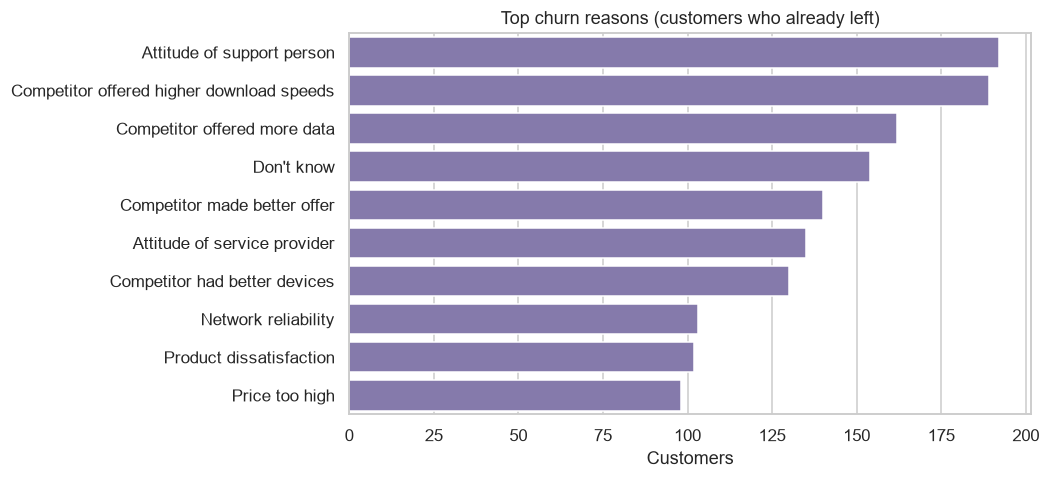

In [22]:
if "Churn Reason" in df.columns:
    reasons = df.loc[df[TARGET] == 1, "Churn Reason"].value_counts().head(10)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    sns.barplot(x=reasons.values, y=reasons.index, orient="h", ax=ax, color="#8172b3")
    ax.set_title("Top churn reasons (customers who already left)")
    ax.set_xlabel("Customers")
    ax.set_ylabel("")
    fig.savefig(FIG_DIR / "06_churn_reasons.png", bbox_inches="tight")
    plt.show()